In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, roc_auc_score, confusion_matrix,classification_report, roc_curve)
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

Dataset 1: Teleco customer churn prediction using KNN algorithm

In [12]:
telco = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [13]:
print(f"Shape: {telco.shape}")
telco.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


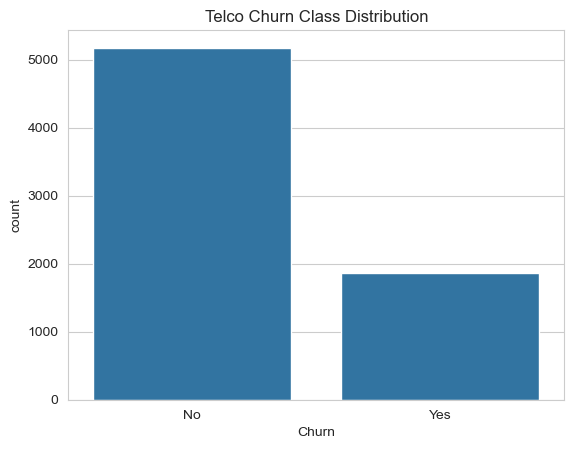

In [14]:
# Churn rate check
print(telco['Churn'].value_counts(normalize=True).round(3))
sns.countplot(data=telco, x='Churn')
plt.title('Telco Churn Class Distribution')
plt.show()

1.2 Data cleaning

In [16]:
# TotalCharges is stored as text and has blank entries for new customers 
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')
print(f"Missing TotalCharges values: {telco['TotalCharges'].isna().sum()}")
telco = telco.dropna(subset=['TotalCharges'])

# Drop identifier column 
telco = telco.drop(columns=['customerID'])

# Encode target
telco['Churn'] = telco['Churn'].map({'Yes': 1, 'No': 0})

# categorical features
cat_cols = telco.select_dtypes(include='object').columns.tolist()
telco_encoded = pd.get_dummies(telco, columns=cat_cols, drop_first=True)
print(f"Encoded shape: {telco_encoded.shape}")

Missing TotalCharges values: 11
Encoded shape: (7032, 31)


1.3 Train KNN model

In [23]:
X_telco = telco_encoded.drop(columns=['Churn'])
y_telco = telco_encoded['Churn']

X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    X_telco, y_telco, test_size=0.2, random_state=42, stratify=y_telco)

# kNN implementation
scaler_t = StandardScaler()
X_train_t_scaled = scaler_t.fit_transform(X_train_t)
X_test_t_scaled = scaler_t.transform(X_test_t)

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_train_t_scaled, y_train_t)

y_pred_knn = knn.predict(X_test_t_scaled)
y_prob_knn = knn.predict_proba(X_test_t_scaled)[:, 1]

1.4 Evaluation

Accuracy:  0.771
Precision: 0.573
Recall:    0.543
F1-score:  0.558
ROC-AUC:   0.805


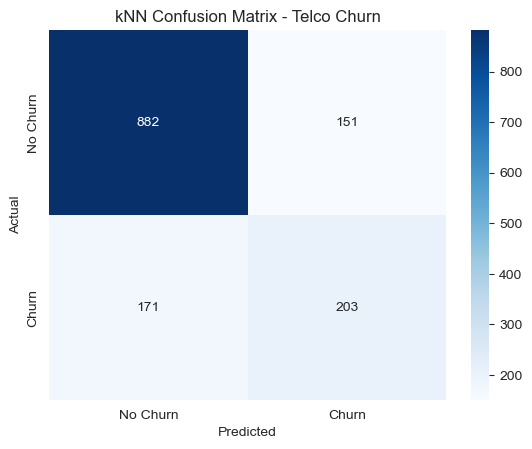

In [26]:
acc_knn = accuracy_score(y_test_t, y_pred_knn)
prec_knn = precision_score(y_test_t, y_pred_knn)
rec_knn = recall_score(y_test_t, y_pred_knn)
f1_knn = f1_score(y_test_t, y_pred_knn)
auc_knn = roc_auc_score(y_test_t, y_prob_knn)

print(f"Accuracy:  {acc_knn:.3f}")
print(f"Precision: {prec_knn:.3f}")
print(f"Recall:    {rec_knn:.3f}")
print(f"F1-score:  {f1_knn:.3f}")
print(f"ROC-AUC:   {auc_knn:.3f}")

cm_knn = confusion_matrix(y_test_t, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', #displaying heat map
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('kNN Confusion Matrix - Telco Churn')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Dataset 2 Bank customer churn

2.1 Load

In [57]:
bank = pd.read_csv('Bank Customer Churn Prediction.csv')

In [59]:
print(f"Shape: {bank.shape}")

Shape: (10000, 12)


In [61]:
print("Columns found:", bank.columns.tolist())
print("Shape:", bank.shape)
bank.head()

Columns found: ['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']
Shape: (10000, 12)


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


churn
0    0.796
1    0.204
Name: proportion, dtype: float64


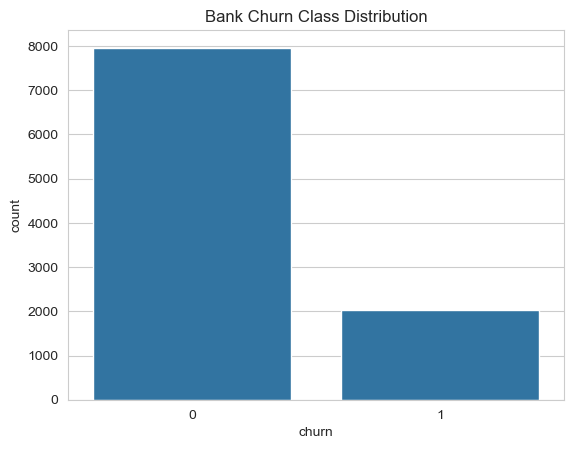

In [44]:
print(bank['churn'].value_counts(normalize=True).round(3))
sns.countplot(data=bank, x='churn')
plt.title('Bank Churn Class Distribution')
plt.show()

2.2 Data cleaning

In [46]:
# Drop identifier column
bank = bank.drop(columns=['customer_id'])

# categorical features
bank_encoded = pd.get_dummies(bank, columns=['country', 'gender'], drop_first=True)
print(f"Encoded shape: {bank_encoded.shape}")
print(f"Missing values: {bank_encoded.isna().sum().sum()}")

Encoded shape: (10000, 12)
Missing values: 0


2.3 Training the model using random forest algorithm

In [48]:
X_bank = bank_encoded.drop(columns=['churn'])
y_bank = bank_encoded['churn']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_bank, y_bank, test_size=0.2, random_state=42, stratify=y_bank)

# implementing randon forest classifier
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
rf.fit(X_train_b, y_train_b)

y_pred_rf = rf.predict(X_test_b)
y_prob_rf = rf.predict_proba(X_test_b)[:, 1]

2.4 Evaluation

Accuracy:  0.868
Precision: 0.820
Recall:    0.447
F1-score:  0.579
ROC-AUC:   0.864


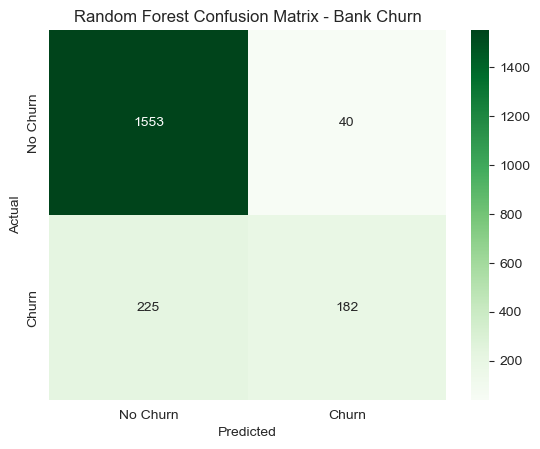

In [49]:
acc_rf = accuracy_score(y_test_b, y_pred_rf)
prec_rf = precision_score(y_test_b, y_pred_rf)
rec_rf = recall_score(y_test_b, y_pred_rf)
f1_rf = f1_score(y_test_b, y_pred_rf)
auc_rf = roc_auc_score(y_test_b, y_prob_rf)

print(f"Accuracy:  {acc_rf:.3f}")
print(f"Precision: {prec_rf:.3f}")
print(f"Recall:    {rec_rf:.3f}")
print(f"F1-score:  {f1_rf:.3f}")
print(f"ROC-AUC:   {auc_rf:.3f}")

cm_rf = confusion_matrix(y_test_b, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title('Random Forest Confusion Matrix - Bank Churn')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

3.1 Feature importance 

age                 0.309933
products_number     0.221854
balance             0.108349
credit_score        0.084370
estimated_salary    0.083031
active_member       0.065044
country_Germany     0.047172
tenure              0.042938
gender_Male         0.017621
credit_card         0.010370
country_Spain       0.009318
dtype: float64


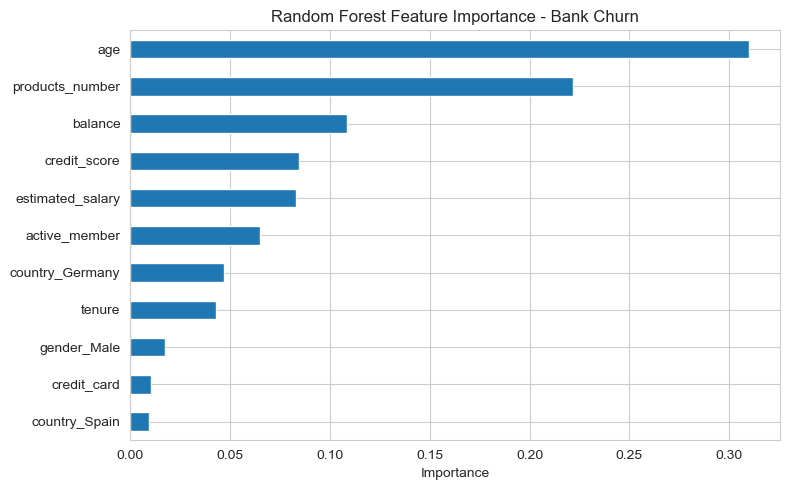

In [50]:
importances = pd.Series(rf.feature_importances_, index=X_bank.columns).sort_values(ascending=False)
print(importances)

plt.figure(figsize=(8,5))
importances.plot(kind='barh')
plt.title('Random Forest Feature Importance - Bank Churn')
plt.xlabel('Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()